In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split


In [2]:
dataset = '1) iris.csv'

In [4]:
df = pd.read_csv(dataset)

In [5]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [6]:
y = df.pop("species")

In [7]:
X = df

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X,y)

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier


In [10]:
model = make_pipeline(StandardScaler(), DecisionTreeClassifier())

In [11]:
model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('decisiontreeclassifier', DecisionTreeClassifier())])

In [12]:
from sklearn.tree import plot_tree

[Text(0.4, 0.9166666666666666, 'petal_width <= -0.542\ngini = 0.666\nsamples = 112\nvalue = [36, 36, 40]\nclass = virginica'),
 Text(0.3, 0.75, 'gini = 0.0\nsamples = 36\nvalue = [36, 0, 0]\nclass = setosa'),
 Text(0.35, 0.8333333333333333, 'True  '),
 Text(0.5, 0.75, 'petal_width <= 0.563\ngini = 0.499\nsamples = 76\nvalue = [0, 36, 40]\nclass = virginica'),
 Text(0.45, 0.8333333333333333, '  False'),
 Text(0.2, 0.5833333333333334, 'petal_length <= 0.674\ngini = 0.184\nsamples = 39\nvalue = [0, 35, 4]\nclass = versicolor'),
 Text(0.1, 0.4166666666666667, 'gini = 0.0\nsamples = 34\nvalue = [0, 34, 0]\nclass = versicolor'),
 Text(0.3, 0.4166666666666667, 'petal_width <= 0.433\ngini = 0.32\nsamples = 5\nvalue = [0, 1, 4]\nclass = virginica'),
 Text(0.2, 0.25, 'gini = 0.0\nsamples = 3\nvalue = [0, 0, 3]\nclass = virginica'),
 Text(0.4, 0.25, 'sepal_width <= -0.436\ngini = 0.5\nsamples = 2\nvalue = [0, 1, 1]\nclass = versicolor'),
 Text(0.3, 0.08333333333333333, 'gini = 0.0\nsamples = 1\nv

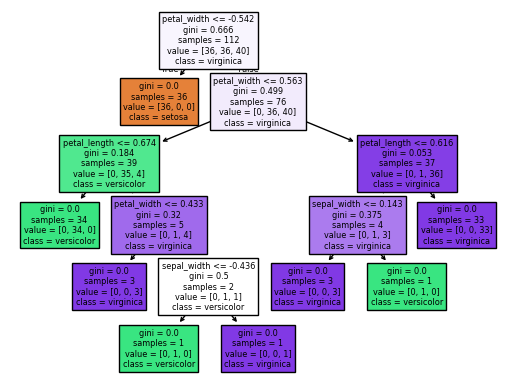

In [14]:
tree = model.named_steps["decisiontreeclassifier"]
plot_tree(tree, feature_names=X.columns, class_names=y.unique(), filled=True)

In [18]:
path = tree.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas

In [19]:
ccp_alphas

array([0.        , 0.00714286, 0.00868726, 0.04981685, 0.25686878,
       0.32747046])

In [27]:
model_pruned = make_pipeline(StandardScaler(), DecisionTreeClassifier(ccp_alpha=ccp_alphas[2]))

In [28]:
model_pruned.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(ccp_alpha=np.float64(0.008687258687258696)))])

[Text(0.4, 0.875, 'petal_length <= -0.764\ngini = 0.666\nsamples = 112\nvalue = [36, 36, 40]\nclass = virginica'),
 Text(0.2, 0.625, 'gini = 0.0\nsamples = 36\nvalue = [36, 0, 0]\nclass = setosa'),
 Text(0.30000000000000004, 0.75, 'True  '),
 Text(0.6, 0.625, 'petal_width <= 0.563\ngini = 0.499\nsamples = 76\nvalue = [0, 36, 40]\nclass = virginica'),
 Text(0.5, 0.75, '  False'),
 Text(0.4, 0.375, 'petal_length <= 0.674\ngini = 0.184\nsamples = 39\nvalue = [0, 35, 4]\nclass = versicolor'),
 Text(0.2, 0.125, 'gini = 0.0\nsamples = 34\nvalue = [0, 34, 0]\nclass = versicolor'),
 Text(0.6, 0.125, 'gini = 0.32\nsamples = 5\nvalue = [0, 1, 4]\nclass = virginica'),
 Text(0.8, 0.375, 'gini = 0.053\nsamples = 37\nvalue = [0, 1, 36]\nclass = virginica')]

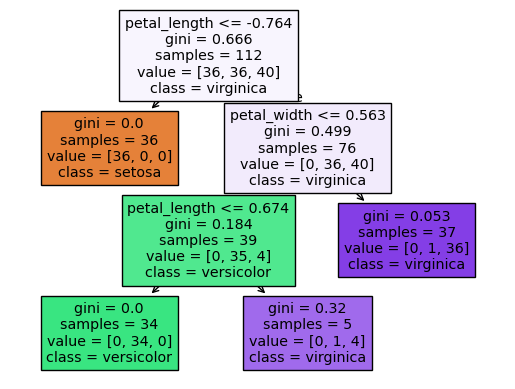

In [29]:
tree_pruned = model_pruned.named_steps["decisiontreeclassifier"]
plot_tree(tree_pruned, feature_names=X.columns, class_names=y.unique(), filled=True)

In [30]:
from sklearn.metrics import accuracy_score, f1_score

print("Accuracy for both models")
print(accuracy_score(y_test, model.predict(X_test)))
print(accuracy_score(y_test, model_pruned.predict(X_test)))

print("F1 score for both models")

print(f1_score(y_test, model.predict(X_test), average="macro"))
print(f1_score(y_test, model_pruned.predict(X_test), average="macro"))

Accuracy for both models
0.9736842105263158
0.9736842105263158
F1 score for both models
0.9717813051146384
0.9717813051146384
